# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Ruchitha Musku
**Course:** MSCS 634 – Advanced Big Data and Data Mining
**Assignment:** Lab 4 – Regression Analysis with Regularization Techniques
**Date:** October 2026

---

**Objective.** Use the scikit-learn Diabetes dataset to build and compare Simple Linear, Multiple, Polynomial, Ridge and Lasso regression models, evaluate them with MAE, MSE, RMSE and R², and visualize how model complexity and regularization affect over- and underfitting.

## Setup: Imports and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## Step 1: Data Preparation

### 1.1 Load the dataset
The Diabetes dataset has **442 patients** and **10 baseline features** (age, sex, BMI, average blood pressure and six blood-serum measurements). The target is a quantitative measure of **disease progression one year after baseline**.

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()          # 10 features + 'target'
X = diabetes.data
y = diabetes.target

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("Features:", list(X.columns))
df.head()

Shape: 442 rows x 11 columns
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0000
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0000
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0000
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0000
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0000


In [3]:
# Feature descriptions (from the dataset documentation)
feature_desc = {
    "age": "Age in years",
    "sex": "Sex",
    "bmi": "Body mass index",
    "bp":  "Average blood pressure",
    "s1":  "tc  - total serum cholesterol",
    "s2":  "ldl - low-density lipoproteins",
    "s3":  "hdl - high-density lipoproteins",
    "s4":  "tch - total cholesterol / HDL",
    "s5":  "ltg - log of serum triglycerides level",
    "s6":  "glu - blood sugar level",
}
pd.DataFrame.from_dict(feature_desc, orient="index", columns=["Description"])

,Description
age,Age in years
sex,Sex
bmi,Body mass index
bp,Average blood pressure
s1,tc - total serum cholesterol
s2,ldl - low-density lipoproteins
s3,hdl - high-density lipoproteins
s4,tch - total cholesterol / HDL
s5,ltg - log of serum triglycerides level
s6,glu - blood sugar level


### 1.2 Explore features, target and distributions

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0000,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0000,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0000,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0000,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0000,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0000,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0000,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0000,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0000,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0000,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


**Note:** The features in `load_diabetes()` are already **mean-centered and scaled** (each column has mean 0 and unit Euclidean norm), which is why the values are small and centered on zero. The target is on its original scale (roughly 25–346).

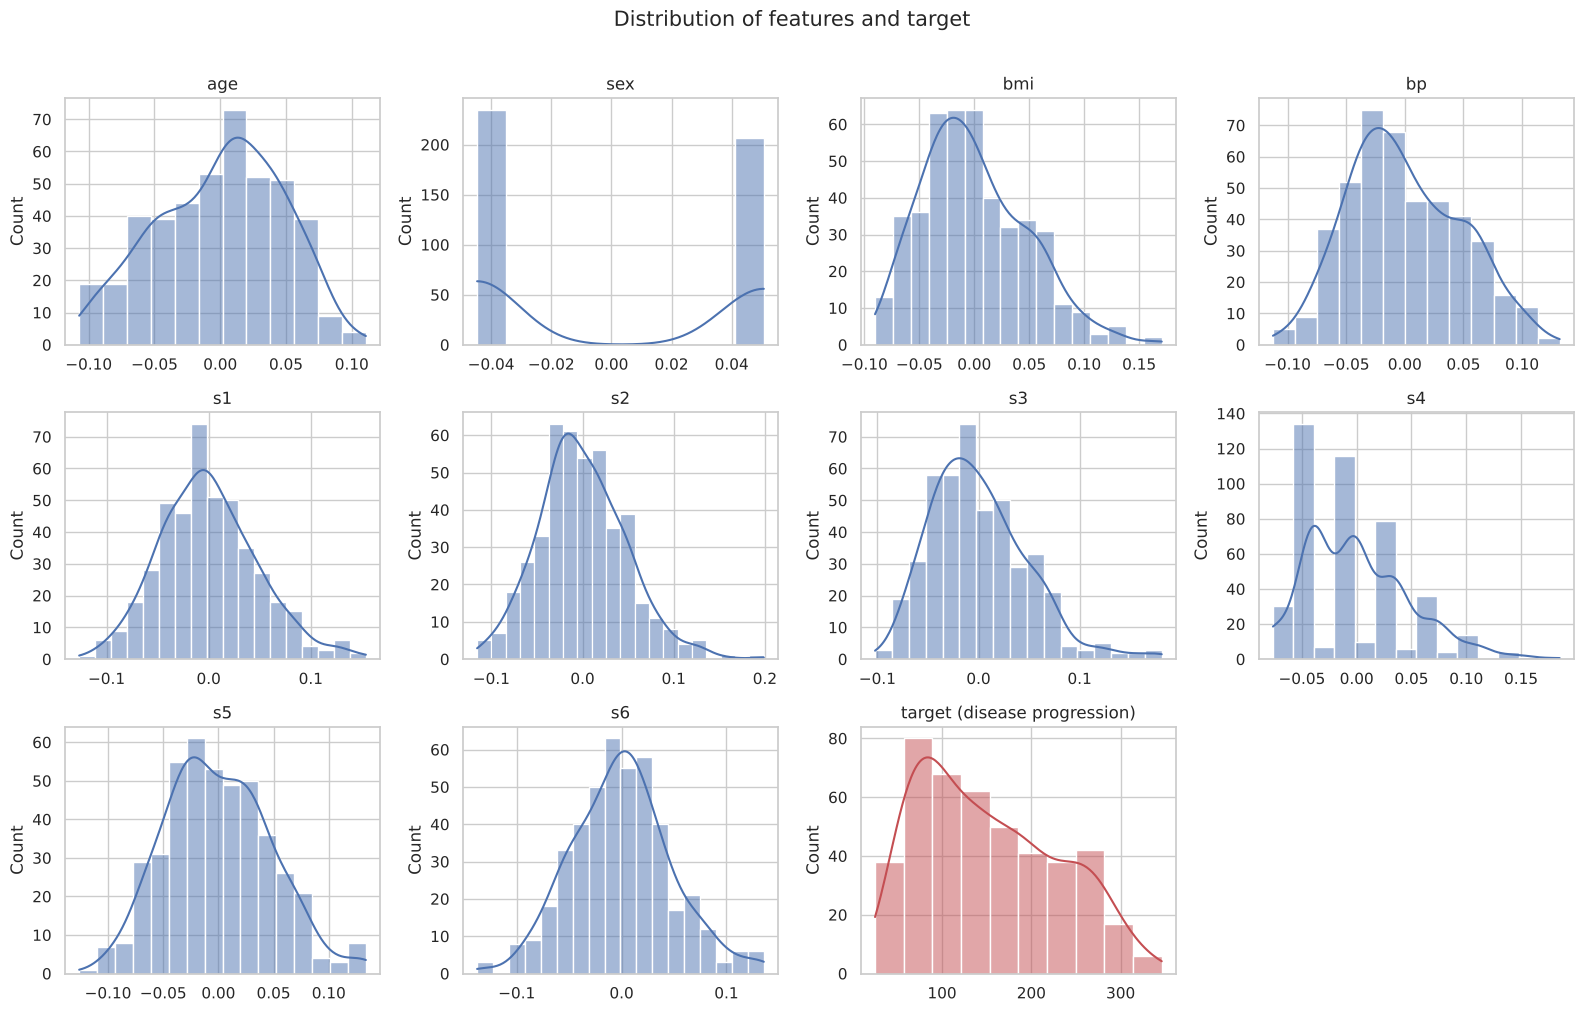

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0" if col != "target" else "#C44E52")
    ax.set_title(col if col != "target" else "target (disease progression)")
    ax.set_xlabel("")
for ax in axes.flat[len(df.columns):]:
    ax.axis("off")
fig.suptitle("Distribution of features and target", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

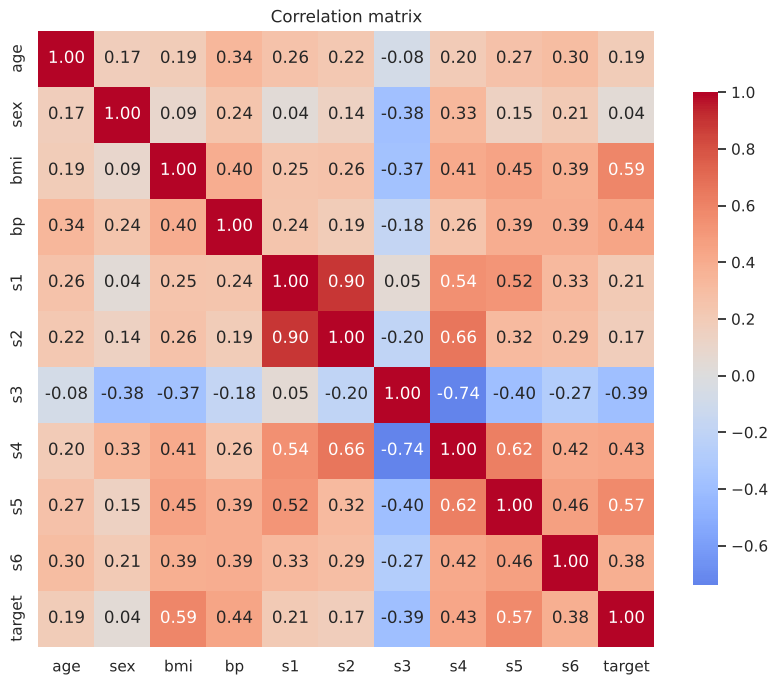

Correlation of each feature with the target:


bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
s3    -0.3948
Name: target, dtype: float64

In [7]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation matrix")
plt.show()

print("Correlation of each feature with the target:")
corr["target"].drop("target").sort_values(ascending=False)

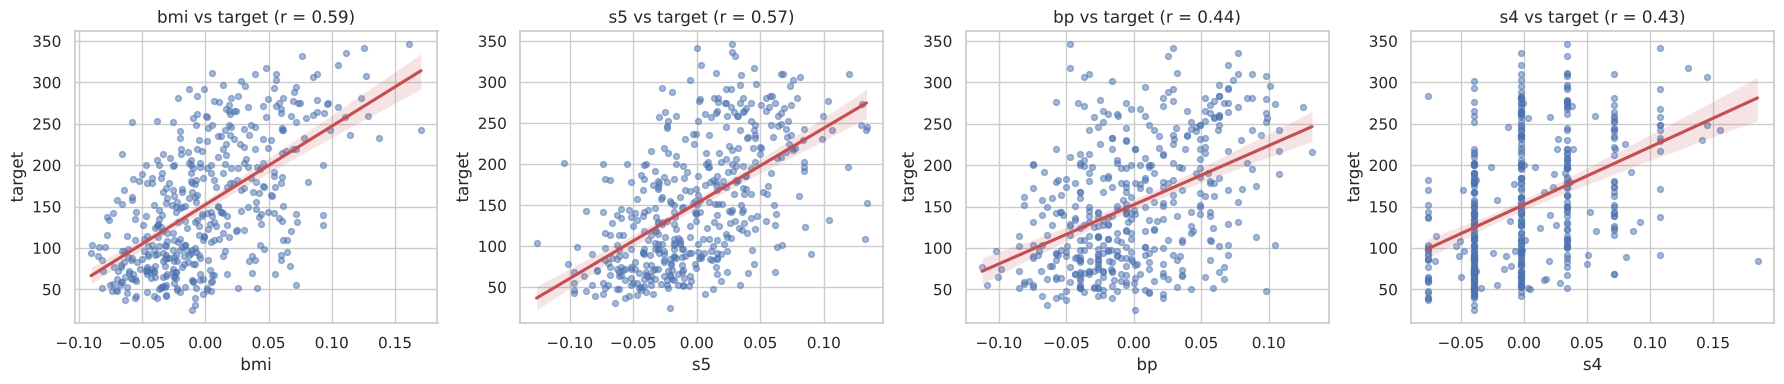

In [8]:
top = corr["target"].drop("target").abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, top):
    sns.regplot(x=df[col], y=df["target"], ax=ax, scatter_kws={"alpha": .5, "s": 18}, line_kws={"color": "#C44E52"})
    ax.set_title(f"{col} vs target (r = {corr.loc[col, 'target']:.2f})")
plt.tight_layout()
plt.show()

### 1.3 Data cleaning

In [9]:
print("Missing values per column:")
print(df.isnull().sum().to_string())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Data types:", df.dtypes.unique())

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0

Total missing values: 0
Duplicate rows: 0
Data types: [dtype('float64')]


Potential outliers per column (1.5 x IQR rule):
age       0
sex       0
bmi       3
bp        0
s1        8
s2        7
s3        7
s4        2
s5        4
s6        9
target    0


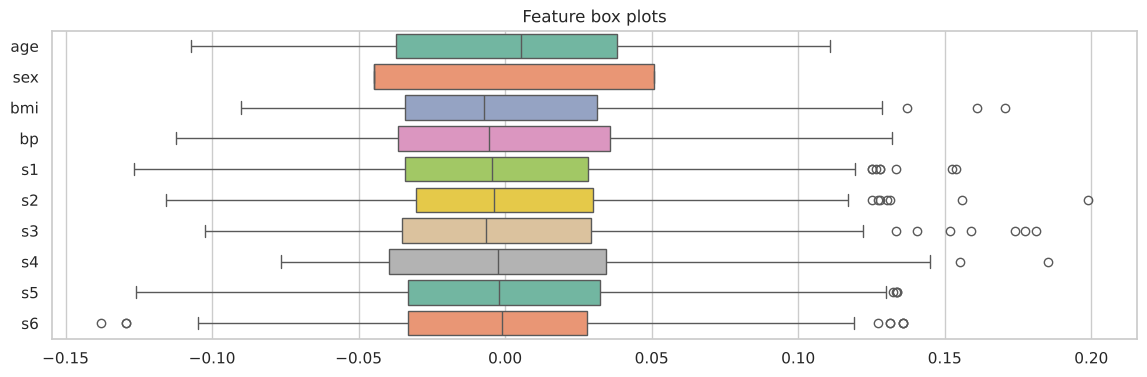

In [10]:
# Outlier check with the IQR rule (reported, not removed)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outliers = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
print("Potential outliers per column (1.5 x IQR rule):")
print(outliers.to_string())

plt.figure(figsize=(14, 4))
sns.boxplot(data=X, orient="h", palette="Set2")
plt.title("Feature box plots")
plt.show()

**Cleaning summary:** There are no missing values, no duplicate rows and every column is numeric, so no imputation or type conversion is needed. A few points fall outside the 1.5×IQR range, but they are plausible clinical values, so they are kept rather than removed (with only 442 rows, dropping data would cost more than it gains). Because the features are already centered and scaled, an additional `StandardScaler` is used inside the model pipelines so that polynomial features and regularization penalties operate on a consistent scale.

### 1.4 Train/test split and evaluation helper
The same **80/20 split** (`random_state=42`) is used for every model, so all results are directly comparable.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

results = []   # collects test-set metrics for the final comparison

def evaluate(name, model, Xtr, Xte, ytr=y_train, yte=y_test, store=True, verbose=True):
    """Fit-agnostic evaluation: returns train & test MAE, MSE, RMSE, R²."""
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    m = {
        "Model": name,
        "MAE": mean_absolute_error(yte, p_te),
        "MSE": mean_squared_error(yte, p_te),
        "RMSE": np.sqrt(mean_squared_error(yte, p_te)),
        "R2": r2_score(yte, p_te),
        "Train RMSE": np.sqrt(mean_squared_error(ytr, p_tr)),
        "Train R2": r2_score(ytr, p_tr),
    }
    if store:
        results[:] = [r for r in results if r["Model"] != name] + [m]
    if verbose:
        print(f"{name}")
        print(f"  Test  -> MAE: {m['MAE']:.2f} | MSE: {m['MSE']:.2f} | RMSE: {m['RMSE']:.2f} | R²: {m['R2']:.4f}")
        print(f"  Train -> RMSE: {m['Train RMSE']:.2f} | R²: {m['Train R2']:.4f}")
    return m, p_te

def plot_pred_vs_actual(ax, y_true, y_pred, title, color="#4C72B0"):
    ax.scatter(y_true, y_pred, alpha=.65, color=color, edgecolor="white", s=45)
    lims = [min(y_true.min(), y_pred.min()) - 10, max(y_true.max(), y_pred.max()) + 10]
    ax.plot(lims, lims, "--", color="gray", lw=1.5, label="Perfect prediction")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Actual disease progression"); ax.set_ylabel("Predicted")
    ax.set_title(f"{title}\nR² = {r2_score(y_true, y_pred):.3f}")
    ax.legend(loc="upper left")

Training set: 353 samples | Test set: 89 samples


## Step 2: Simple Linear Regression

**BMI** is used as the single independent variable because it has the strongest correlation with the target (r ≈ 0.59). The model is

$$\hat{y} = \beta_0 + \beta_1 \cdot \text{bmi}$$

In [12]:
feature = "bmi"
Xtr_s, Xte_s = X_train[[feature]], X_test[[feature]]

slr = LinearRegression().fit(Xtr_s, y_train)
print(f"Intercept (β0): {slr.intercept_:.2f}")
print(f"Slope     (β1): {slr.coef_[0]:.2f}\n")
slr_metrics, slr_pred = evaluate("Simple Linear (bmi)", slr, Xtr_s, Xte_s)

Intercept (β0): 152.00
Slope     (β1): 998.58

Simple Linear (bmi)
  Test  -> MAE: 52.26 | MSE: 4061.83 | RMSE: 63.73 | R²: 0.2334
  Train -> RMSE: 62.08 | R²: 0.3657


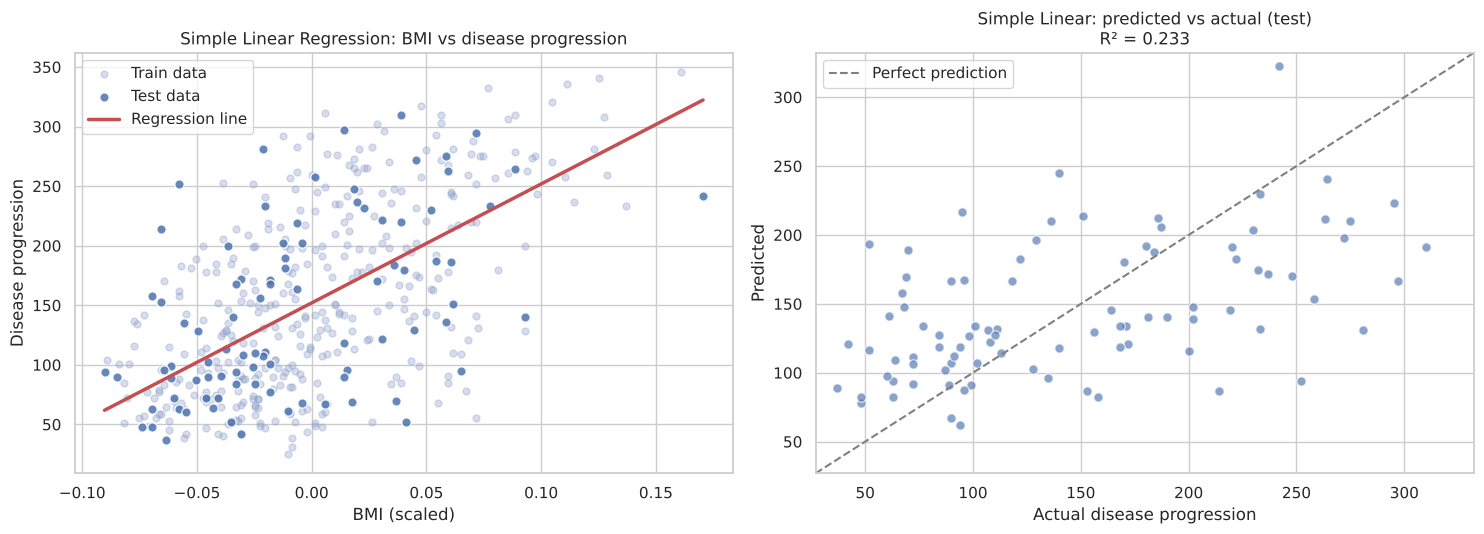

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.scatter(X_train[feature], y_train, alpha=.35, color="#8DA0CB", label="Train data", s=25)
ax.scatter(X_test[feature], y_test, alpha=.85, color="#4C72B0", edgecolor="white", label="Test data", s=45)
xs = np.linspace(X[feature].min(), X[feature].max(), 100).reshape(-1, 1)
ax.plot(xs, slr.predict(pd.DataFrame(xs, columns=[feature])), color="#C44E52", lw=2.5, label="Regression line")
ax.set_xlabel("BMI (scaled)"); ax.set_ylabel("Disease progression")
ax.set_title("Simple Linear Regression: BMI vs disease progression")
ax.legend()

plot_pred_vs_actual(axes[1], y_test, slr_pred, "Simple Linear: predicted vs actual (test)")
plt.tight_layout(); plt.show()

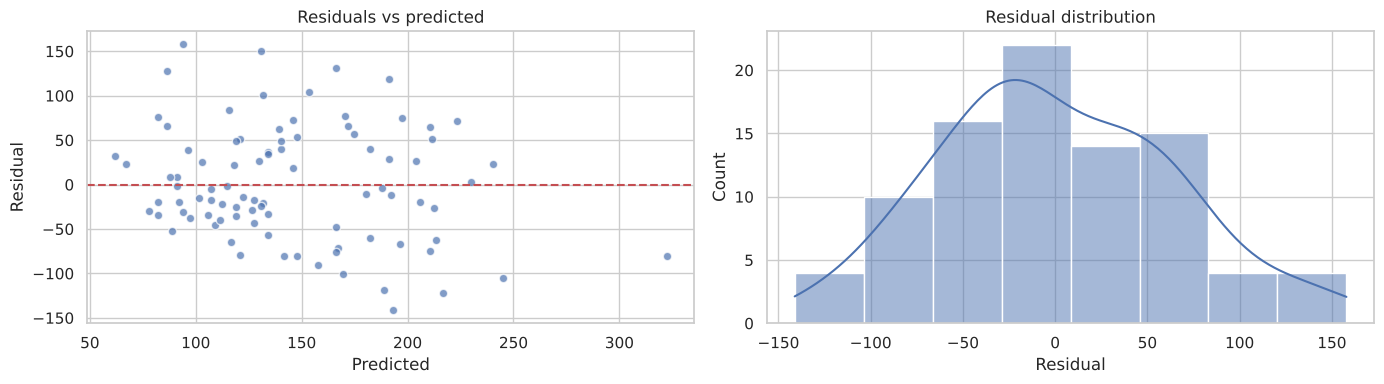

In [14]:
# Residual analysis
resid = y_test - slr_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(slr_pred, resid, alpha=.7, color="#4C72B0", edgecolor="white")
axes[0].axhline(0, color="#C44E52", ls="--")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs predicted")
sns.histplot(resid, kde=True, ax=axes[1], color="#4C72B0")
axes[1].set_title("Residual distribution"); axes[1].set_xlabel("Residual")
plt.tight_layout(); plt.show()

### Observations: Simple Linear Regression
* BMI alone explains about **23% of the variance** on the test set (R² = 0.233) and about 37% on the training set. The 5-fold cross-validated R² (≈ 0.32) sits between the two, which shows that a single 89-sample test split is somewhat noisy.
* The average prediction is off by about **52 units** (MAE) on a target that ranges from 25 to 346, and RMSE (63.7) is noticeably larger than MAE, so a few large errors pull the squared metrics up.
* The positive slope confirms that **higher BMI is associated with faster disease progression**, but the wide scatter around the line shows that BMI on its own leaves most of the variation unexplained. The model **underfits**: it is too simple for this problem.
* The residuals are centered on zero with no strong curvature, so a straight line is a reasonable shape for BMI. The missing accuracy comes from the information in the *other* features, not from nonlinearity.

## Step 3: Multiple Regression

All 10 features are used as independent variables:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_{10} x_{10}$$

In [15]:
mlr = LinearRegression().fit(X_train, y_train)
mlr_metrics, mlr_pred = evaluate("Multiple Linear (all 10)", mlr, X_train, X_test)

coef_mlr = pd.Series(mlr.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("\nIntercept:", round(mlr.intercept_, 2))
coef_mlr.to_frame("Coefficient")

Multiple Linear (all 10)
  Test  -> MAE: 42.79 | MSE: 2900.19 | RMSE: 53.85 | R²: 0.4526
  Train -> RMSE: 53.56 | R²: 0.5279

Intercept: 151.35


,Coefficient
s1,-931.4888
s5,736.1989
bmi,542.4288
s2,518.0623
bp,347.7038
s4,275.3179
sex,-241.9644
s3,163.4200
s6,48.6707
age,37.9040


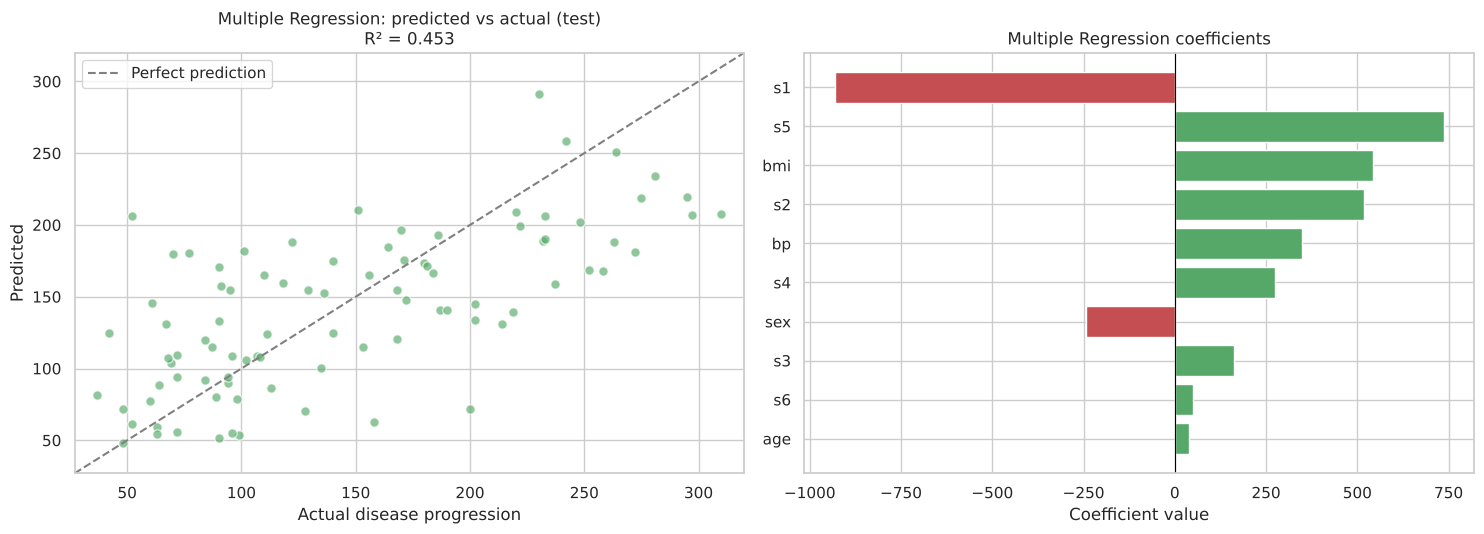

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_pred_vs_actual(axes[0], y_test, mlr_pred, "Multiple Regression: predicted vs actual (test)", color="#55A868")

colors = ["#55A868" if c > 0 else "#C44E52" for c in coef_mlr]
axes[1].barh(coef_mlr.index[::-1], coef_mlr.values[::-1], color=colors[::-1])
axes[1].axvline(0, color="black", lw=.8)
axes[1].set_title("Multiple Regression coefficients"); axes[1].set_xlabel("Coefficient value")
plt.tight_layout(); plt.show()

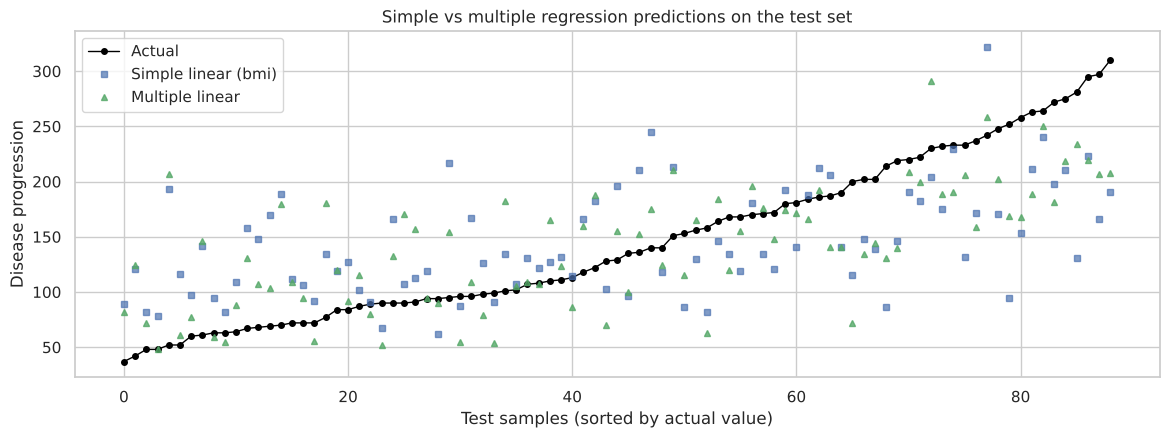

In [17]:
# Simple vs multiple, side by side on the same test points
fig, ax = plt.subplots(figsize=(14, 4.5))
order = np.argsort(y_test.values)
ax.plot(y_test.values[order], "o-", color="black", ms=4, lw=1, label="Actual")
ax.plot(slr_pred[order], "s", color="#4C72B0", ms=4, alpha=.7, label="Simple linear (bmi)")
ax.plot(mlr_pred[order], "^", color="#55A868", ms=4, alpha=.8, label="Multiple linear")
ax.set_xlabel("Test samples (sorted by actual value)"); ax.set_ylabel("Disease progression")
ax.set_title("Simple vs multiple regression predictions on the test set")
ax.legend(); plt.show()

In [18]:
# 5-fold cross-validation for a more stable estimate than a single split
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, mdl, data in [("Simple Linear (bmi)", LinearRegression(), X[[feature]]),
                        ("Multiple Linear", LinearRegression(), X)]:
    s = cross_val_score(mdl, data, y, cv=cv, scoring="r2")
    print(f"{name:22s} 5-fold CV R²: {s.mean():.4f} ± {s.std():.4f}")

Simple Linear (bmi)    5-fold CV R²: 0.3207 ± 0.0776
Multiple Linear        5-fold CV R²: 0.4785 ± 0.0850


### Observations: Multiple Regression
* Using all 10 features roughly **doubles the explained variance**: test R² rises from 0.233 to **0.453**, MAE drops from 52.3 to **42.8** and RMSE from 63.7 to **53.9**. Cross-validation agrees (0.32 → 0.48).
* Train R² (0.528) and test R² (0.453) are close, so the model is **not badly overfitting**. With only 10 coefficients and 353 training rows it has enough data for a stable fit.
* **BMI, s5 (log triglycerides) and bp (blood pressure)** have large positive effects, matching the correlation analysis.
* The coefficients for **s1 (−931) and s2 (+518)** are large and have opposite signs even though s1 and s2 are highly correlated (r ≈ 0.90 in the heatmap). This is a classic sign of **multicollinearity**: the model offsets one against the other, which makes the individual coefficients unstable and hard to interpret. Regularization in Step 5 addresses this directly.

## Step 4: Polynomial Regression

Polynomial regression extends linear regression by adding powers (and, with several features, interaction terms) of the inputs, e.g. for degree 2:

$$\hat{y} = \beta_0 + \sum_i \beta_i x_i + \sum_{i \le j} \beta_{ij} x_i x_j$$

The model is still linear in its coefficients, so it is fit with ordinary least squares. Two experiments are run:
1. **Single feature (BMI)** with degrees 1–15, which is easy to visualize.
2. **All 10 features** with degrees 1–3, where the number of terms grows very quickly.

### 4.1 Polynomial regression on BMI (single feature)

In [19]:
def poly_model(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), LinearRegression())

degrees = range(1, 16)
rows = []
for d in degrees:
    m = poly_model(d).fit(Xtr_s, y_train)
    rows.append({"Degree": d,
                 "Train RMSE": np.sqrt(mean_squared_error(y_train, m.predict(Xtr_s))),
                 "Test RMSE":  np.sqrt(mean_squared_error(y_test,  m.predict(Xte_s))),
                 "Train R2": r2_score(y_train, m.predict(Xtr_s)),
                 "Test R2":  r2_score(y_test,  m.predict(Xte_s))})
poly_bmi_df = pd.DataFrame(rows).set_index("Degree")
poly_bmi_df

,Train RMSE,Test RMSE,Train R2,Test R2
Degree,,,,
1,62.0815,63.7325,0.3657,0.2334
2,62.0430,63.9142,0.3665,0.2290
3,62.0359,63.7530,0.3667,0.2329
4,61.8955,65.0088,0.3695,0.2023
5,61.8366,63.9206,0.3707,0.2288
6,61.7682,63.0839,0.3721,0.2489
7,61.6754,64.7541,0.3740,0.2086
8,61.1159,88.7430,0.3853,-0.4864
9,61.1137,84.8842,0.3853,-0.3600


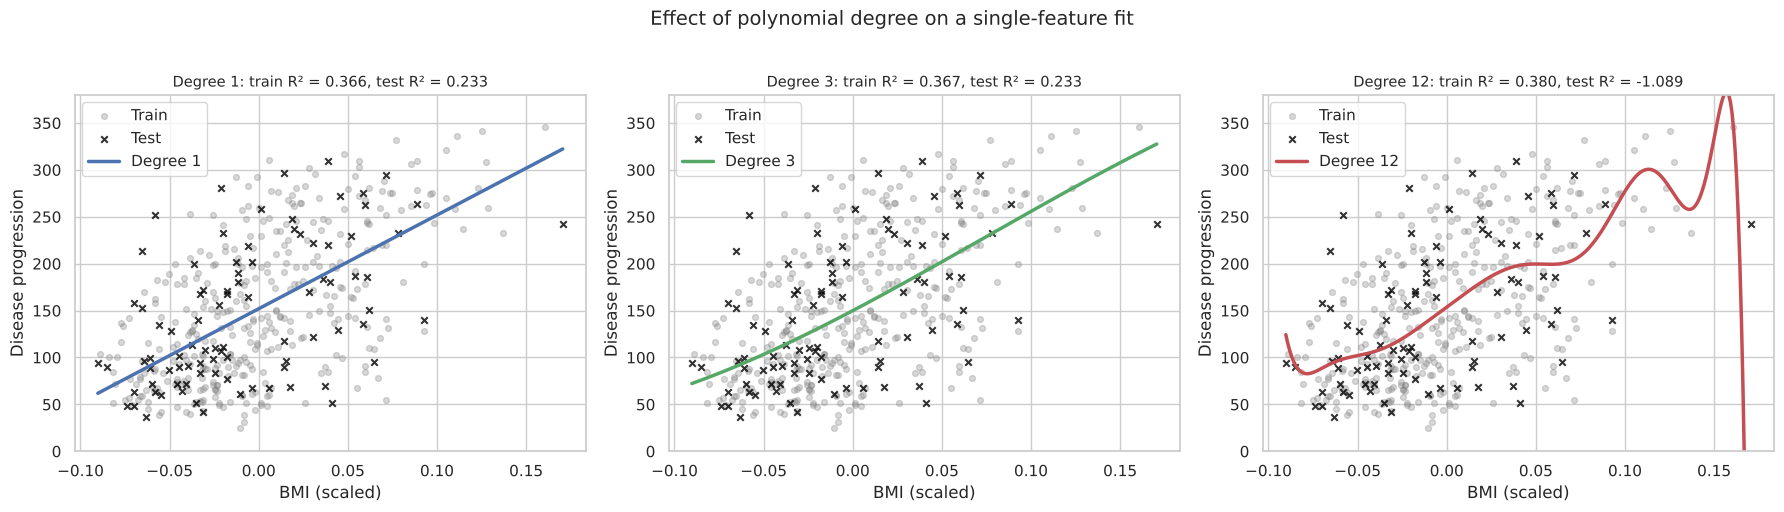

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
xs = pd.DataFrame(np.linspace(X[feature].min(), X[feature].max(), 300), columns=[feature])
for ax, d, c in zip(axes, [1, 3, 12], ["#4C72B0", "#55A868", "#C44E52"]):
    m = poly_model(d).fit(Xtr_s, y_train)
    ax.scatter(X_train[feature], y_train, alpha=.3, color="gray", s=18, label="Train")
    ax.scatter(X_test[feature], y_test, alpha=.8, color="black", s=22, marker="x", label="Test")
    ax.plot(xs[feature], m.predict(xs), color=c, lw=2.5, label=f"Degree {d}")
    ax.set_ylim(0, 380)
    ax.set_title(f"Degree {d}: train R² = {r2_score(y_train, m.predict(Xtr_s)):.3f}, test R² = {r2_score(y_test, m.predict(Xte_s)):.3f}", fontsize=10.5)
    ax.set_xlabel("BMI (scaled)"); ax.set_ylabel("Disease progression"); ax.legend(loc="upper left")
fig.suptitle("Effect of polynomial degree on a single-feature fit", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

### 4.2 Polynomial regression on all features

In [21]:
rows, poly_models = [], {}
for d in [1, 2, 3]:
    m = poly_model(d).fit(X_train, y_train)
    poly_models[d] = m
    n_terms = m.named_steps["polynomialfeatures"].n_output_features_
    rows.append({"Degree": d, "# Terms": n_terms,
                 "Train RMSE": np.sqrt(mean_squared_error(y_train, m.predict(X_train))),
                 "Test RMSE":  np.sqrt(mean_squared_error(y_test,  m.predict(X_test))),
                 "Train R2": r2_score(y_train, m.predict(X_train)),
                 "Test R2":  r2_score(y_test,  m.predict(X_test))})
poly_all_df = pd.DataFrame(rows).set_index("Degree")
poly_all_df

,# Terms,Train RMSE,Test RMSE,Train R2,Test R2
Degree,,,,,
1,10,53.5588,53.8534,0.5279,0.4526
2,65,48.9197,55.6420,0.6062,0.4156
3,285,27.3842,284.5712,0.8766,-14.2847


In [22]:
# Store the representative polynomial models for the final comparison
best_bmi_deg = int(poly_bmi_df["Test R2"].idxmax())
poly_bmi_best = poly_model(best_bmi_deg).fit(Xtr_s, y_train)
_ , poly_bmi_pred = evaluate(f"Polynomial bmi (deg {best_bmi_deg})", poly_bmi_best, Xtr_s, Xte_s)
print()
_ , poly2_pred = evaluate("Polynomial all (deg 2)", poly_models[2], X_train, X_test)
print()
_ , poly3_pred = evaluate("Polynomial all (deg 3)", poly_models[3], X_train, X_test)

Polynomial bmi (deg 6)
  Test  -> MAE: 51.12 | MSE: 3979.58 | RMSE: 63.08 | R²: 0.2489
  Train -> RMSE: 61.77 | R²: 0.3721

Polynomial all (deg 2)
  Test  -> MAE: 43.58 | MSE: 3096.03 | RMSE: 55.64 | R²: 0.4156
  Train -> RMSE: 48.92 | R²: 0.6062

Polynomial all (deg 3)
  Test  -> MAE: 162.32 | MSE: 80980.76 | RMSE: 284.57 | R²: -14.2847
  Train -> RMSE: 27.38 | R²: 0.8766


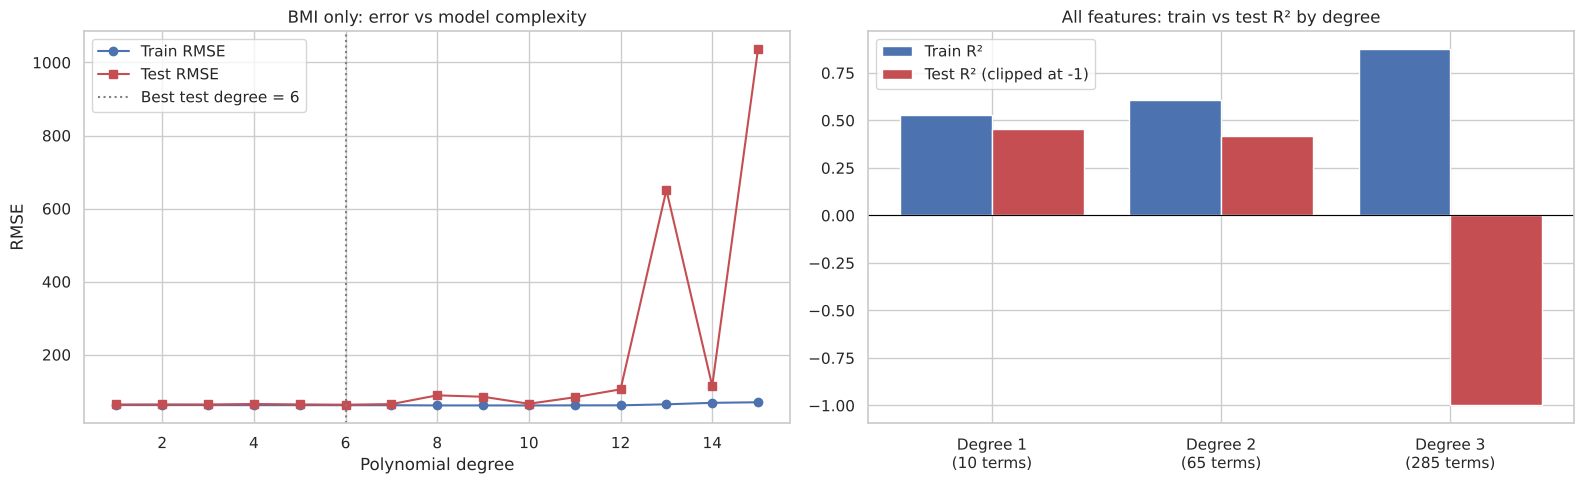

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.plot(poly_bmi_df.index, poly_bmi_df["Train RMSE"], "o-", label="Train RMSE", color="#4C72B0")
ax.plot(poly_bmi_df.index, poly_bmi_df["Test RMSE"], "s-", label="Test RMSE", color="#C44E52")
ax.axvline(best_bmi_deg, ls=":", color="gray", label=f"Best test degree = {best_bmi_deg}")
ax.set_xlabel("Polynomial degree"); ax.set_ylabel("RMSE")
ax.set_title("BMI only: error vs model complexity"); ax.legend()

ax = axes[1]
x = np.arange(len(poly_all_df))
ax.bar(x - .2, poly_all_df["Train R2"], .4, label="Train R²", color="#4C72B0")
ax.bar(x + .2, poly_all_df["Test R2"].clip(lower=-1), .4, label="Test R² (clipped at -1)", color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels([f"Degree {d}\n({t} terms)" for d, t in zip(poly_all_df.index, poly_all_df["# Terms"])])
ax.axhline(0, color="black", lw=.8)
ax.set_title("All features: train vs test R² by degree"); ax.legend()
plt.tight_layout(); plt.show()

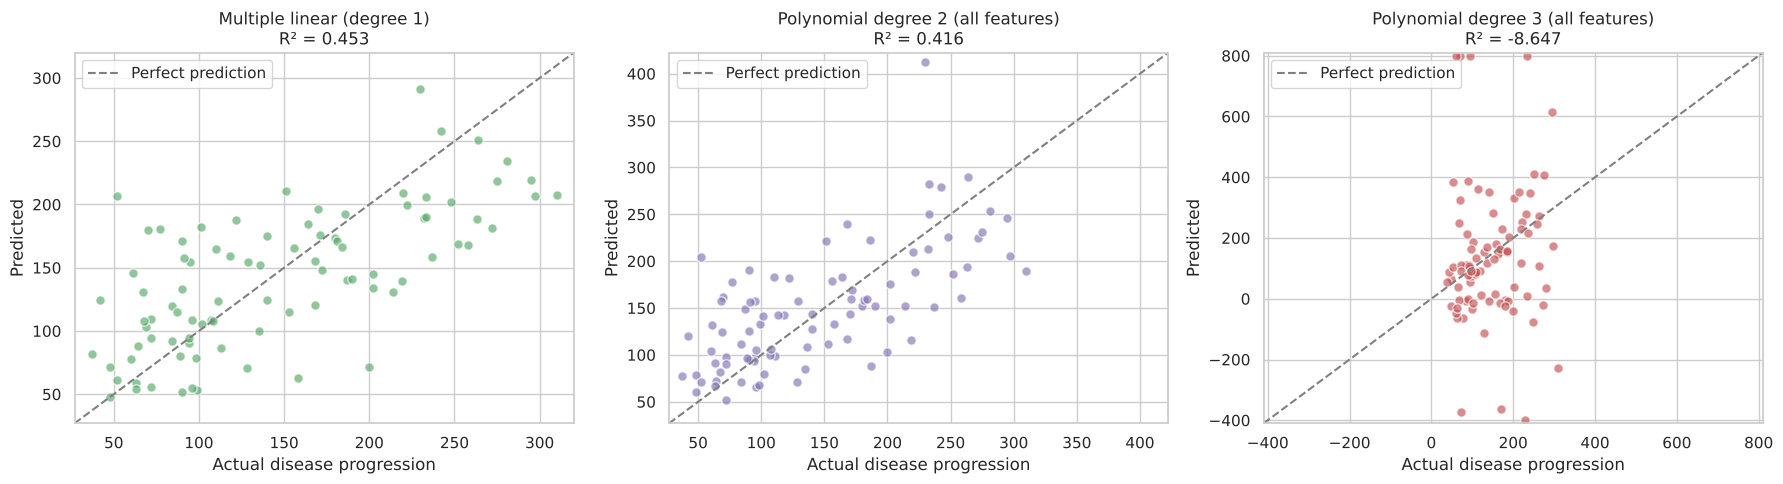

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_pred_vs_actual(axes[0], y_test, mlr_pred, "Multiple linear (degree 1)", "#55A868")
plot_pred_vs_actual(axes[1], y_test, poly2_pred, "Polynomial degree 2 (all features)", "#8172B2")
plot_pred_vs_actual(axes[2], y_test, np.clip(poly3_pred, -400, 800), "Polynomial degree 3 (all features)", "#C44E52")
plt.tight_layout(); plt.show()

### Observations: Polynomial Regression and the Bias-Variance Trade-off
**Single feature (BMI):**
* Degrees 1–7 all perform about the same (test R² ≈ 0.20–0.25), so the BMI relationship is **essentially linear** and curved terms add almost nothing. Degree 6 had the best test score (0.249), only slightly better than the straight line (0.233). Because this "best" degree was picked by looking at the test set, its small advantage should not be over-interpreted.
* From degree 8 onward, the test error **swings wildly** (test R² becomes negative at degrees 8, 9, 11–15) while training error barely changes. The degree-12 plot shows why: the curve bends sharply at the edges of the data to chase individual training points, and those wiggles produce absurd predictions for new patients. This is **overfitting**.
* At very high degrees (13–15), even the training R² falls. Raising a feature to the 13th–15th power produces enormous, nearly collinear columns, and least squares becomes numerically unstable. This is another reason why high-degree polynomials are fragile.

**All 10 features:**
| Degree | Terms | Train R² | Test R² | Interpretation |
|---|---|---|---|---|
| 1 | 10 | 0.528 | 0.453 | Good balance |
| 2 | 65 | 0.606 | 0.416 | Mild overfitting: train ↑, test ↓ |
| 3 | 285 | 0.877 | **−14.28** | Severe overfitting: 285 parameters for 353 rows |

* Adding interaction and squared terms **improves the training fit but hurts the test fit**. At degree 3 the model nearly memorizes the training data (train R² = 0.88) and its test predictions are far worse than simply predicting the mean (negative R²).
* **Underfitting** shows up at the low end (simple linear on BMI: high error on both train and test). **Overfitting** shows up at the high end (large gap between train and test). Degree 1 with all features is the best unregularized choice here.
* Degree-2 features *do* contain some useful signal (train R² rises), but without a penalty the extra 55 terms add more variance than they remove bias. This motivates regularization.

## Step 5: Regularization with Ridge and Lasso Regression

Regularization adds a penalty on coefficient size to the least-squares loss:

| Model | Objective | Effect |
|---|---|---|
| **Ridge (L2)** | $\min \; \|y - X\beta\|^2 + \alpha \sum \beta_j^2$ | Shrinks all coefficients smoothly toward 0; keeps every feature |
| **Lasso (L1)** | $\min \; \tfrac{1}{2n}\|y - X\beta\|^2 + \alpha \sum \lvert\beta_j\rvert$ | Shrinks and can set coefficients **exactly to 0** (feature selection) |

`alpha` controls the strength: `alpha = 0` is ordinary least squares; larger values give simpler, more biased but lower-variance models. Each model is applied to:
* the **10 original features** (linear), and
* the **degree-2 polynomial features** (65 terms), where overfitting is a real risk and regularization should matter most.

All features are standardized first so the penalty treats every coefficient equally.

### 5.1 Effect of alpha

In [25]:
alphas = np.logspace(-3, 3, 50)
Xtr_p2 = poly_models[2][:-1].transform(X_train)   # scaled degree-2 features
Xte_p2 = poly_models[2][:-1].transform(X_test)
scaler_lin = StandardScaler().fit(X_train)
Xtr_l, Xte_l = scaler_lin.transform(X_train), scaler_lin.transform(X_test)

def sweep(Model, Xtr, Xte):
    tr, te, coefs = [], [], []
    for a in alphas:
        m = Model(alpha=a, max_iter=50000).fit(Xtr, y_train) if Model is Lasso else Model(alpha=a).fit(Xtr, y_train)
        tr.append(r2_score(y_train, m.predict(Xtr))); te.append(r2_score(y_test, m.predict(Xte)))
        coefs.append(m.coef_)
    return np.array(tr), np.array(te), np.array(coefs)

sw = {("Ridge", "Linear"): sweep(Ridge, Xtr_l, Xte_l),
      ("Lasso", "Linear"): sweep(Lasso, Xtr_l, Xte_l),
      ("Ridge", "Poly-2"): sweep(Ridge, Xtr_p2, Xte_p2),
      ("Lasso", "Poly-2"): sweep(Lasso, Xtr_p2, Xte_p2)}

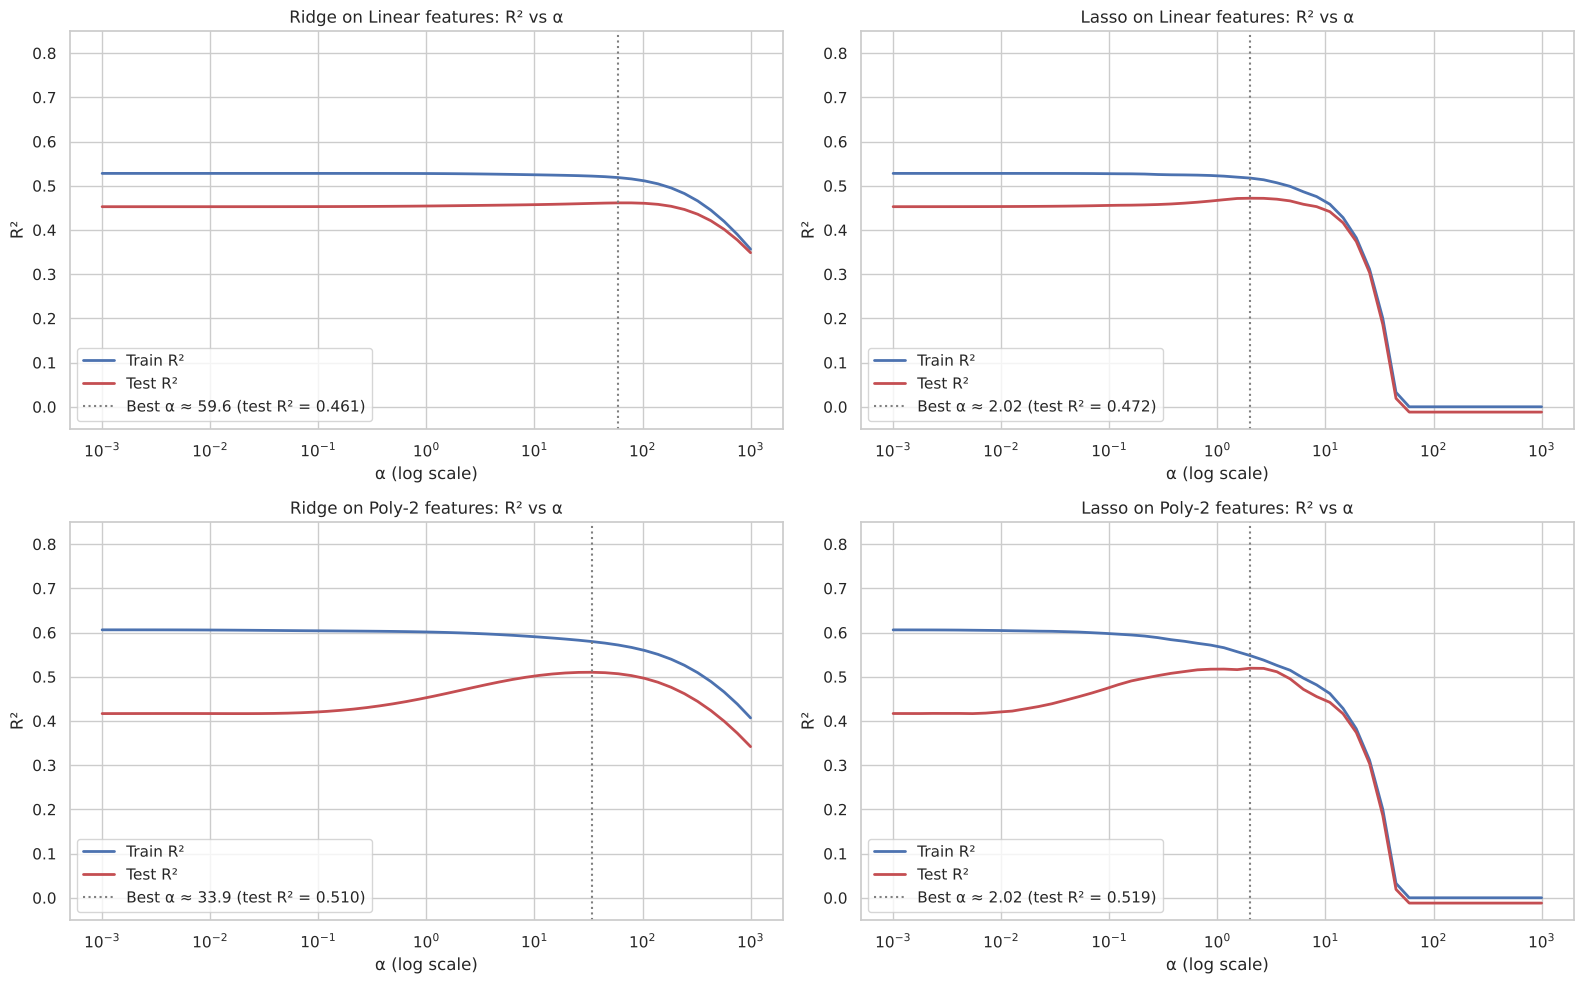

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, key in zip(axes.flat, sw):
    tr, te, _ = sw[key]
    ax.semilogx(alphas, tr, "-", color="#4C72B0", lw=2, label="Train R²")
    ax.semilogx(alphas, te, "-", color="#C44E52", lw=2, label="Test R²")
    best = alphas[te.argmax()]
    ax.axvline(best, ls=":", color="gray", label=f"Best α ≈ {best:.3g} (test R² = {te.max():.3f})")
    ax.set_ylim(-0.05, 0.85)
    ax.set_title(f"{key[0]} on {key[1]} features: R² vs α"); ax.set_xlabel("α (log scale)"); ax.set_ylabel("R²")
    ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

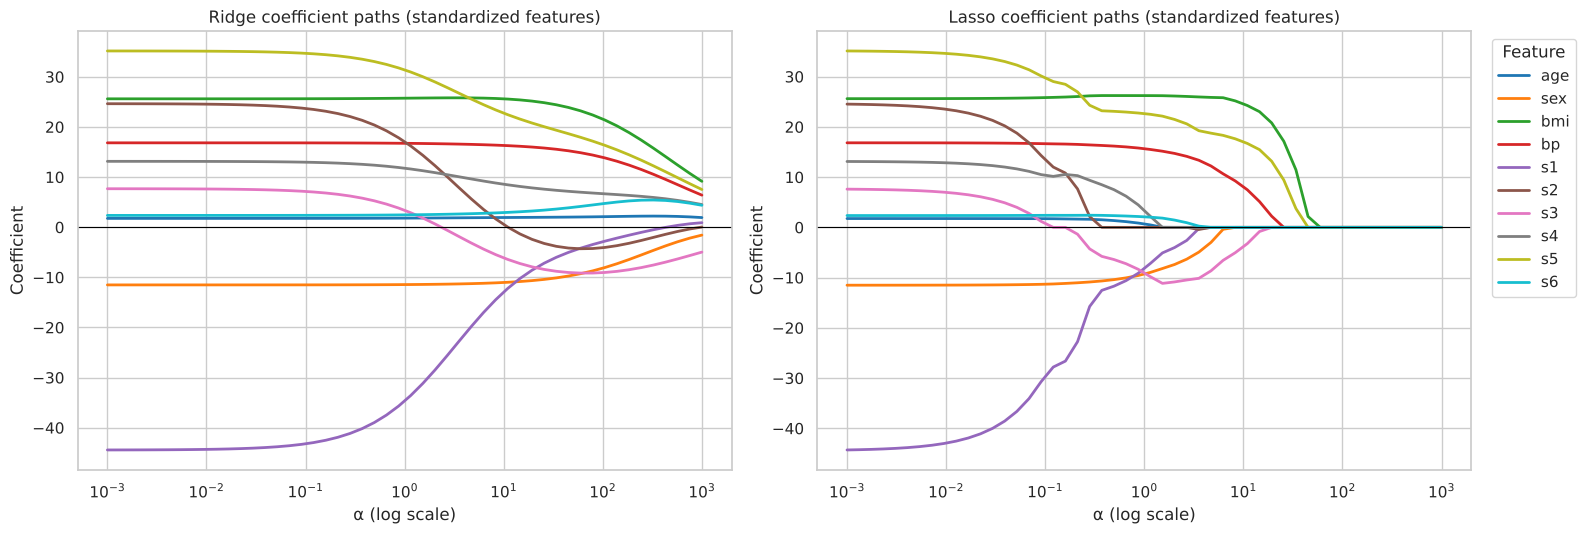

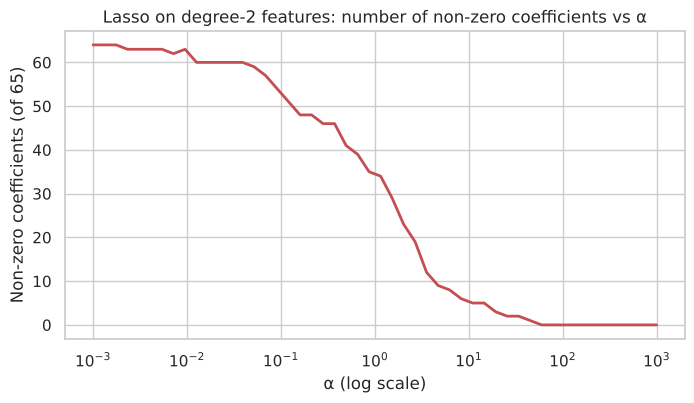

In [27]:
# Coefficient paths on the 10 original features
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
palette = sns.color_palette("tab10", 10)
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    coefs = sw[(name, "Linear")][2]
    for j, col in enumerate(X.columns):
        ax.semilogx(alphas, coefs[:, j], color=palette[j], lw=2, label=col)
    ax.axhline(0, color="black", lw=.8)
    ax.set_title(f"{name} coefficient paths (standardized features)")
    ax.set_xlabel("α (log scale)"); ax.set_ylabel("Coefficient")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Feature")
plt.tight_layout(); plt.show()

nz = (np.abs(sw[("Lasso", "Poly-2")][2]) > 1e-8).sum(axis=1)
plt.figure(figsize=(8, 4))
plt.semilogx(alphas, nz, color="#C44E52", lw=2)
plt.title("Lasso on degree-2 features: number of non-zero coefficients vs α")
plt.xlabel("α (log scale)"); plt.ylabel("Non-zero coefficients (of 65)")
plt.show()

### 5.2 Choosing alpha with cross-validation
The sweep above uses the test set only to *illustrate* the effect of α. To pick α properly, without peeking at the test data, `RidgeCV` and `LassoCV` choose it with 5-fold cross-validation on the training set only.

In [28]:
cv_alphas = np.logspace(-3, 3, 100)
reg_models = {
    "Ridge (linear)": make_pipeline(StandardScaler(), RidgeCV(alphas=cv_alphas, cv=cv)),
    "Lasso (linear)": make_pipeline(StandardScaler(), LassoCV(alphas=cv_alphas, cv=cv, max_iter=50000, random_state=RANDOM_STATE)),
    "Ridge (poly deg 2)": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                        RidgeCV(alphas=cv_alphas, cv=cv)),
    "Lasso (poly deg 2)": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                        LassoCV(alphas=cv_alphas, cv=cv, max_iter=50000, random_state=RANDOM_STATE)),
}
reg_preds, reg_info = {}, []
for name, m in reg_models.items():
    m.fit(X_train, y_train)
    est = m[-1]
    _, reg_preds[name] = evaluate(name, m, X_train, X_test)
    nnz = int((np.abs(est.coef_) > 1e-8).sum())
    reg_info.append({"Model": name, "Chosen α": est.alpha_, "Non-zero coefs": f"{nnz} / {len(est.coef_)}"})
    print(f"  chosen α = {est.alpha_:.4g}, non-zero coefficients = {nnz}/{len(est.coef_)}\n")
pd.DataFrame(reg_info).set_index("Model")

Ridge (linear)
  Test  -> MAE: 42.81 | MSE: 2892.40 | RMSE: 53.78 | R²: 0.4541
  Train -> RMSE: 53.57 | R²: 0.5277
  chosen α = 0.9326, non-zero coefficients = 10/10

Lasso (linear)
  Test  -> MAE: 42.84 | MSE: 2854.97 | RMSE: 53.43 | R²: 0.4611
  Train -> RMSE: 53.76 | R²: 0.5244
  chosen α = 0.5337, non-zero coefficients = 9/10



Ridge (poly deg 2)
  Test  -> MAE: 41.08 | MSE: 2626.80 | RMSE: 51.25 | R²: 0.5042
  Train -> RMSE: 51.36 | R²: 0.5659
  chosen α = 81.11, non-zero coefficients = 65/65



Lasso (poly deg 2)
  Test  -> MAE: 41.34 | MSE: 2575.71 | RMSE: 50.75 | R²: 0.5138
  Train -> RMSE: 53.57 | R²: 0.5277
  chosen α = 3.275, non-zero coefficients = 15/65



,Chosen α,Non-zero coefs
Model,,
Ridge (linear),0.9326,10 / 10
Lasso (linear),0.5337,9 / 10
Ridge (poly deg 2),81.1131,65 / 65
Lasso (poly deg 2),3.2745,15 / 65


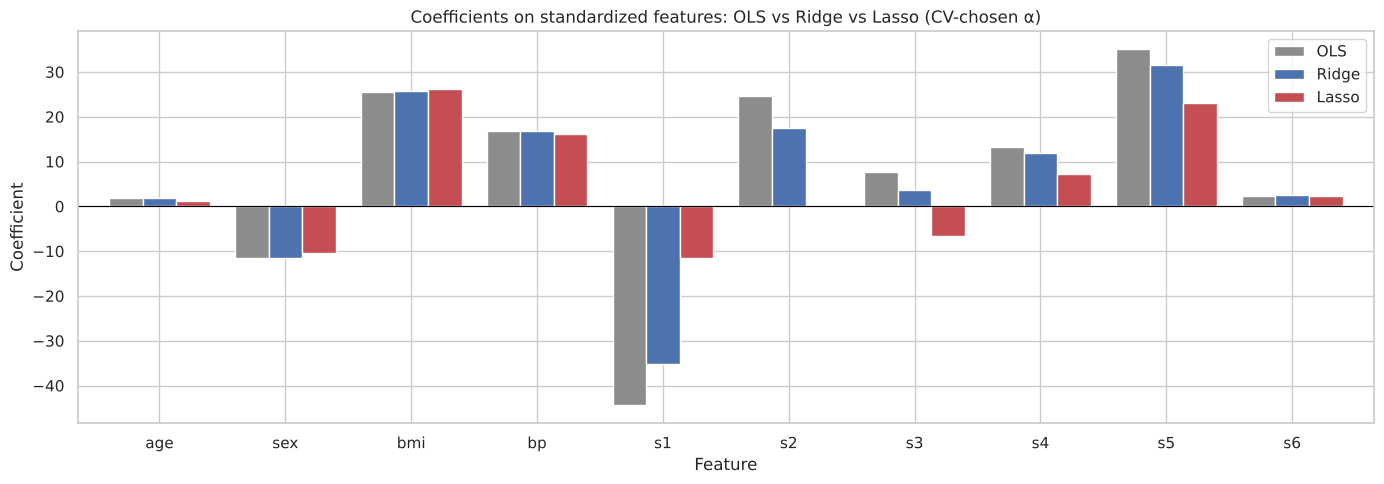

,OLS,Ridge,Lasso
age,1.7538,1.8045,1.2981
sex,-11.5118,-11.4522,-10.3171
bmi,25.6071,25.7270,26.2257
bp,16.8289,16.7398,16.1344
s1,-44.4489,-35.1845,-11.4316
s2,24.6410,17.4500,0.0000
s3,7.6770,3.5956,-6.6073
s4,13.1388,11.8367,7.1824
s5,35.1612,31.5772,23.0546
s6,2.3514,2.4520,2.3140


In [29]:
coef_cmp = pd.DataFrame({
    "OLS":   mlr.coef_ * X_train.std(ddof=0).values,   # convert to standardized-feature scale for fair comparison
    "Ridge": reg_models["Ridge (linear)"][-1].coef_,
    "Lasso": reg_models["Lasso (linear)"][-1].coef_,
}, index=X.columns)

fig, ax = plt.subplots(figsize=(14, 5))
coef_cmp.plot.bar(ax=ax, color=["#8C8C8C", "#4C72B0", "#C44E52"], width=.8)
ax.axhline(0, color="black", lw=.8)
ax.set_title("Coefficients on standardized features: OLS vs Ridge vs Lasso (CV-chosen α)")
ax.set_ylabel("Coefficient"); ax.set_xlabel("Feature"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
coef_cmp

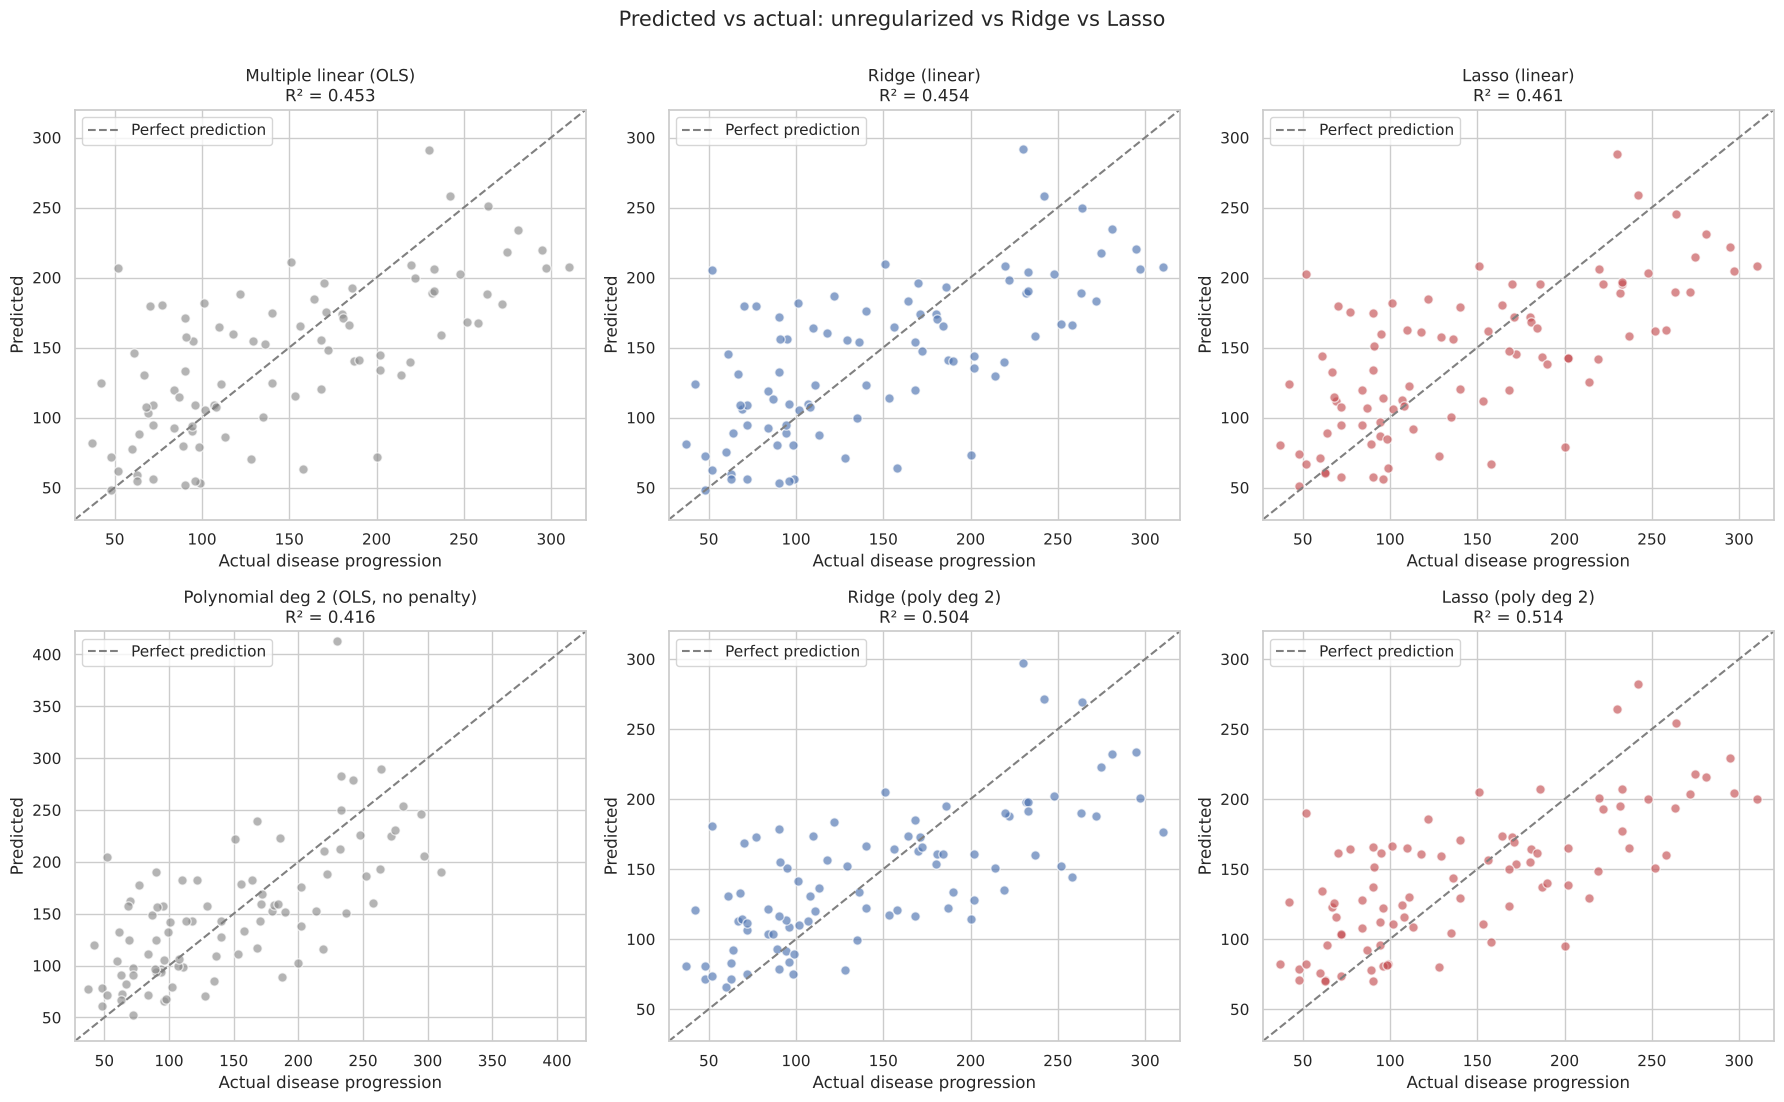

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
plot_pred_vs_actual(axes[0, 0], y_test, mlr_pred, "Multiple linear (OLS)", "#8C8C8C")
plot_pred_vs_actual(axes[0, 1], y_test, reg_preds["Ridge (linear)"], "Ridge (linear)", "#4C72B0")
plot_pred_vs_actual(axes[0, 2], y_test, reg_preds["Lasso (linear)"], "Lasso (linear)", "#C44E52")
plot_pred_vs_actual(axes[1, 0], y_test, poly2_pred, "Polynomial deg 2 (OLS, no penalty)", "#8C8C8C")
plot_pred_vs_actual(axes[1, 1], y_test, reg_preds["Ridge (poly deg 2)"], "Ridge (poly deg 2)", "#4C72B0")
plot_pred_vs_actual(axes[1, 2], y_test, reg_preds["Lasso (poly deg 2)"], "Lasso (poly deg 2)", "#C44E52")
fig.suptitle("Predicted vs actual: unregularized vs Ridge vs Lasso", fontsize=15, y=1.0)
plt.tight_layout(); plt.show()

### Observations: Ridge vs Lasso and the Role of α

**How α controls the model (see R²-vs-α and coefficient-path plots):**
* **Small α (→ 0):** both models behave like ordinary least squares. The curves are flat on the left of every plot and match the unregularized results.
* **Moderate α:** coefficients shrink, variance falls and **test R² rises** to a peak. On the degree-2 features, the test curve climbs from 0.42 to about 0.51–0.52 while training R² drifts down slightly. This is the bias-variance trade-off working in our favor.
* **Large α:** the penalty dominates and the model **underfits**. Ridge shrinks every coefficient gradually toward zero, so its curves decline smoothly. Lasso drives coefficients to exactly zero one after another, and past α ≈ 50 all coefficients are zero, the model predicts the mean and R² falls to 0.

**Ridge vs Lasso:**
* **Ridge (L2)** keeps all features (10/10 and 65/65 non-zero) and spreads the weight across correlated predictors. On the linear features it noticeably shrinks the unstable s1/s2 pair (s1: −44.4 → −35.2, s2: 24.6 → 17.5 in standardized units) while leaving strong predictors such as BMI and bp almost unchanged.
* **Lasso (L1)** performs **automatic feature selection**. On the 10 linear features it drops **s2** entirely and reduces s1 to −11.4, resolving the multicollinearity by keeping one representative of the correlated group. On the 65 degree-2 terms it keeps only **15**, which gives a much simpler and more interpretable model.

**Performance (α chosen by 5-fold CV on the training set):**
* On the **original 10 features**, regularization makes only a small difference (test R² 0.453 → 0.454 Ridge / 0.461 Lasso). The plain linear model was not overfitting much, so there was little variance to remove.
* On the **degree-2 features**, regularization makes a large difference: test R² rises from **0.416 (unpenalized) to 0.504 (Ridge) and 0.514 (Lasso)**, and RMSE drops from 55.6 to about 51. The penalty turns an overfitting model into the **best models in the lab**.
* Lasso (poly 2) also has the **smallest train/test gap** (0.528 vs 0.514), which is a sign of good generalization.

## Step 6: Model Comparison and Analysis

In [31]:
summary = pd.DataFrame(results).set_index("Model")
summary["Overfit gap (Train R2 - Test R2)"] = summary["Train R2"] - summary["R2"]
summary = summary[["MAE", "MSE", "RMSE", "R2", "Train R2", "Overfit gap (Train R2 - Test R2)"]]
summary.sort_values("R2", ascending=False)

,MAE,MSE,RMSE,R2,Train R2,Overfit gap (Train R2 - Test R2)
Model,,,,,,
Lasso (poly deg 2),41.3406,"2,575.7052",50.7514,0.5138,0.5277,0.0138
Ridge (poly deg 2),41.0832,"2,626.8022",51.2523,0.5042,0.5659,0.0617
Lasso (linear),42.8370,"2,854.9685",53.4319,0.4611,0.5244,0.0632
Ridge (linear),42.8111,"2,892.4005",53.7810,0.4541,0.5277,0.0736
Multiple Linear (all 10),42.7941,"2,900.1936",53.8534,0.4526,0.5279,0.0753
Polynomial all (deg 2),43.5817,"3,096.0283",55.6420,0.4156,0.6062,0.1905
Polynomial bmi (deg 6),51.1209,"3,979.5758",63.0839,0.2489,0.3721,0.1232
Simple Linear (bmi),52.2600,"4,061.8259",63.7325,0.2334,0.3657,0.1324
Polynomial all (deg 3),162.3176,"80,980.7566",284.5712,-14.2847,0.8766,15.1613


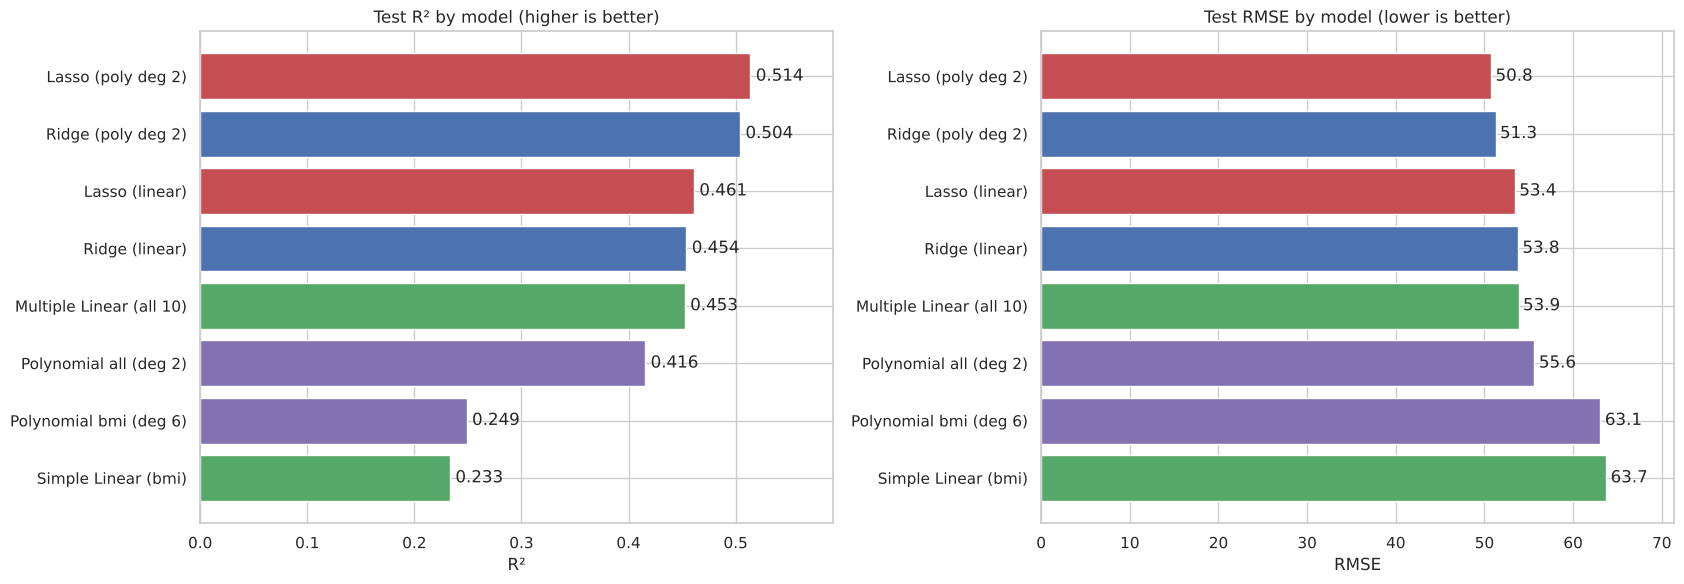

Polynomial all (deg 3) is excluded from the chart because its test error is off the scale:
RMSE   284.5712
R2     -14.2847


In [32]:
plot_df = summary.drop(index=["Polynomial all (deg 3)"]).sort_values("R2")
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

cols = ["#C44E52" if "Lasso" in i else "#4C72B0" if "Ridge" in i else "#8172B2" if "Poly" in i else "#55A868" for i in plot_df.index]
axes[0].barh(plot_df.index, plot_df["R2"], color=cols)
for i, v in enumerate(plot_df["R2"]):
    axes[0].text(v + .005, i, f"{v:.3f}", va="center")
axes[0].set_title("Test R² by model (higher is better)"); axes[0].set_xlabel("R²")
axes[0].set_xlim(0, plot_df["R2"].max() * 1.15)

axes[1].barh(plot_df.index, plot_df["RMSE"], color=cols)
for i, v in enumerate(plot_df["RMSE"]):
    axes[1].text(v + .5, i, f"{v:.1f}", va="center")
axes[1].set_title("Test RMSE by model (lower is better)"); axes[1].set_xlabel("RMSE")
axes[1].set_xlim(0, plot_df["RMSE"].max() * 1.12)
plt.tight_layout(); plt.show()
print("Polynomial all (deg 3) is excluded from the chart because its test error is off the scale:")
print(summary.loc["Polynomial all (deg 3)", ["RMSE", "R2"]].to_string())

In [33]:
# Cross-validated R² for every model on the full dataset (more robust than a single 89-sample test set)
cv_models = {
    "Simple Linear (bmi)": (LinearRegression(), X[[feature]]),
    "Multiple Linear": (LinearRegression(), X),
    "Polynomial all (deg 2)": (poly_model(2), X),
    "Polynomial all (deg 3)": (poly_model(3), X),
    "Ridge (linear)": (make_pipeline(StandardScaler(), Ridge(alpha=reg_models["Ridge (linear)"][-1].alpha_)), X),
    "Lasso (linear)": (make_pipeline(StandardScaler(), Lasso(alpha=reg_models["Lasso (linear)"][-1].alpha_, max_iter=50000)), X),
    "Ridge (poly deg 2)": (make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                         Ridge(alpha=reg_models["Ridge (poly deg 2)"][-1].alpha_)), X),
    "Lasso (poly deg 2)": (make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                         Lasso(alpha=reg_models["Lasso (poly deg 2)"][-1].alpha_, max_iter=50000)), X),
}
cv_rows = []
for name, (m, data) in cv_models.items():
    s = cross_val_score(m, data, y, cv=cv, scoring="r2")
    cv_rows.append({"Model": name, "CV R² mean": s.mean(), "CV R² std": s.std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV R² mean", ascending=False)
cv_df

,CV R² mean,CV R² std
Model,,
Lasso (poly deg 2),0.4852,0.0765
Lasso (linear),0.4794,0.0819
Ridge (linear),0.4791,0.0835
Multiple Linear,0.4785,0.0850
Ridge (poly deg 2),0.4708,0.0630
Polynomial all (deg 2),0.3658,0.1061
Simple Linear (bmi),0.3207,0.0776
Polynomial all (deg 3),-32.6752,33.2376


### Summary and Discussion

**1. How well each model performed (test set, 89 patients)**

| Rank | Model | Test R² | RMSE | MAE | Comment |
|---|---|---|---|---|---|
| 1 | Lasso (poly deg 2) | **0.514** | **50.8** | 41.3 | Best overall; uses only 15 of 65 terms |
| 2 | Ridge (poly deg 2) | 0.504 | 51.3 | **41.1** | Lowest MAE; keeps all 65 terms |
| 3 | Lasso (linear) | 0.461 | 53.4 | 42.8 | Drops s2, slight gain over OLS |
| 4 | Ridge (linear) | 0.454 | 53.8 | 42.8 | Nearly identical to OLS |
| 5 | Multiple Linear | 0.453 | 53.9 | 42.8 | Strong, simple baseline |
| 6 | Polynomial all (deg 2) | 0.416 | 55.6 | 43.6 | Mild overfitting |
| 7 | Polynomial bmi (deg 6) | 0.249 | 63.1 | 51.1 | Barely better than linear BMI |
| 8 | Simple Linear (bmi) | 0.233 | 63.7 | 52.3 | Underfits: one feature isn't enough |
| 9 | Polynomial all (deg 3) | −14.28 | 284.6 | 162.3 | Severe overfitting |

**2. Which models handled overfitting or improved performance**
* **Overfitting** was clearest in the unregularized polynomial models. Degree 3 on all features (285 terms, 353 rows) memorized the training data, and high-degree BMI polynomials gave unstable test predictions.
* **Ridge and Lasso fixed it.** Applying them to the same degree-2 features that overfit without a penalty produced the two best models, with an improvement of about 0.09–0.10 in test R². This is the central result of the lab: regularization lets us use a more flexible feature set **without paying the variance cost**.
* On the plain linear model, regularization had little effect, because that model wasn't overfitting in the first place. Regularization helps most when the number of parameters is large relative to the data.
* **Cross-validation confirms the ranking but narrows the gaps.** Across 5 folds, Lasso (poly 2) is still on top (0.485), with the linear models at about 0.48 and unpenalized poly-2 well behind (0.366). Ridge (poly 2) falls slightly behind the linear models in CV (0.471), so its test-set advantage is partly due to this particular split. The models with R² ≈ 0.46–0.51 are therefore close in practice. The robust conclusions are that (a) using all features matters a lot, (b) unpenalized polynomial expansion hurts, and (c) regularization recovers and slightly improves on the linear baseline.

**3. Insights about the Diabetes dataset**
* **BMI, s5 (log serum triglycerides) and bp (blood pressure)** are consistently the strongest predictors across the correlation analysis, OLS, Ridge and Lasso. They are retained with large weights even under heavy regularization.
* **s1 and s2 (total cholesterol and LDL)** are highly collinear. OLS gives them huge, opposite-signed coefficients, while Lasso keeps s1 and removes s2. Their individual OLS coefficients should not be interpreted directly.
* **sex, age and s6** contribute relatively little once other variables are known.
* The relationships are **mostly linear**. The gain from interaction terms is real but small, and only appears once they are regularized.
* Even the best model explains only about **half the variance** (R² ≈ 0.5) and has a typical error of about 41 units. This suggests that disease progression depends on factors not captured by these 10 baseline measurements (e.g., treatment, genetics, lifestyle), so these models are better suited to identifying risk factors than to precise individual prediction.